# 40_dl: LSTM forecast of next-cycle SOH

**Owner:** Khải Hưng · **Review:** Minh Vũ · **Plan:** `docs/Go.md` GĐ5d, WBS C6.7–C6.10, decisions in `docs/Rec.md` 6.1.

Code lives in `src/lstm_model.py`; this notebook runs it step by step and shows the results.

## Step 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from protocol import load_split
from lstm_model import STEP_FEATURES, WINDOW, check_windows, make_windows

## Step 2. Shared data split

`load_split()` (shared by all four models) keeps tier-A rows without `cap_outlier` / `break_in` and splits by battery. `is_eval` marks the last 40% of each test battery, the rows every model predicts.

In [2]:
train, test = load_split()
assert (len(train), len(test), test.is_eval.sum()) == (947, 528, 213)
len(train), len(test), test.is_eval.sum()

(947, 528, np.int64(213))

## Step 3. Sliding windows (C6.7)

The target cycle *t* is predicted from the 10 cycles *t−9..t*. Each step holds what is known just before that cycle's discharge, the same information set as the SVR features:

| Step feature | Meaning |
|---|---|
| `soh_prev`, `T_max_prev_C` | result of the previous discharge |
| `chg_cc_time_s`, `Re_ohm`, `Rct_ohm`, `log_rest_h` | measured before this discharge |
| `is_4C`, `I_level_A`, `cutoff_V` | fixed operating conditions |

Rules: windows are built inside one battery; windows with missing Re/Rct (before the first EIS of B0005–B0007) are dropped, not filled; the network learns ΔSOH = SOH_t − SOH_{t−1}.

In [3]:
Xtr, dtr, ptr, itr = make_windows(train)
Xte, dte, pte, ite = make_windows(test)
check_windows(train, Xtr, dtr, ptr, itr)   # one battery per window, no same-cycle leakage
check_windows(test, Xte, dte, pte, ite)
assert len(Xtr) == 867 - 2 * 18           # 18 windows each of B0005, B0006 touch missing Re/Rct
assert set(test.index[test.is_eval]) <= set(ite), "every evaluated row needs a window"
print("train", Xtr.shape, " test", Xte.shape)
pd.DataFrame({"train": train.loc[itr].battery_id.value_counts(),
              "test": test.loc[ite].battery_id.value_counts()}).fillna(0).astype(int)

train (831, 10, 9)  test (470, 10, 9)


,train,test
battery_id,,
B0005,139,0
B0006,138,0
B0007,0,139
B0018,122,0
B0033,168,0
B0034,0,184
B0045,57,0
B0046,58,0
B0047,0,58


One window as the network sees it (first training window of B0018): rows are steps *t−9..t*, the target is the ΔSOH of the last row's cycle.

In [4]:
k = np.flatnonzero(train.loc[itr].battery_id.to_numpy() == "B0018")[0]
w = pd.DataFrame(Xtr[k], columns=STEP_FEATURES)
w.insert(0, "cycle_valid", train.cycle_valid.loc[itr[k] - WINDOW + 1:itr[k]].to_numpy())
print(f"target cycle {train.cycle_valid[itr[k]]}: soh_prev {ptr[k]:.4f} + dsoh {dtr[k]:+.4f} "
      f"= soh {train.soh[itr[k]]:.4f}")
w.round(4)

target cycle 11: soh_prev 0.9896 + dsoh -0.0059 = soh 0.9837


,cycle_valid,soh_prev,T_max_prev_C,chg_cc_time_s,Re_ohm,Rct_ohm,log_rest_h,is_4C,I_level_A,cutoff_V
0,2,1.0063,38.101799,3180.187988,0.0627,0.0916,0.4359,0.0,2.0,2.5
1,3,1.0000,38.149899,3178.187988,0.0614,0.0919,0.4360,0.0,2.0,2.5
2,4,0.9981,37.526699,3154.437012,0.0613,0.0914,0.4361,0.0,2.0,2.5
3,5,0.9934,37.062801,3129.266113,0.0614,0.0920,0.0178,0.0,2.0,2.5
4,6,0.9946,38.210999,3178.093994,0.0614,0.0920,0.0179,0.0,2.0,2.5
5,7,0.9923,38.174999,3163.797119,0.0614,0.0920,0.0180,0.0,2.0,2.5
6,8,0.9854,37.640400,3130.327881,0.0614,0.0920,0.0180,0.0,2.0,2.5
7,9,0.9822,37.375999,3111.422119,0.0625,0.0878,0.4365,0.0,2.0,2.5
8,10,0.9794,37.289299,3044.812988,0.0591,0.0899,0.0182,0.0,2.0,2.5
9,11,0.9896,37.523800,3143.672119,0.0591,0.0899,0.0182,0.0,2.0,2.5


ΔSOH per cycle is small and noisy compared with SOH itself; this is what the network has to learn beyond the naive forecast (ΔSOH = 0).

In [5]:
pd.Series(dtr).describe().round(4)

count    831.0000
mean      -0.0019
std        0.0144
min       -0.0554
25%       -0.0074
50%       -0.0034
75%        0.0002
max        0.1249
dtype: float64

## Step 4. Model and training (C6.8)

Architecture fixed in `docs/Go.md` GĐ5d: `LSTM(9 → 32)` → `Dropout(0.2)` → `Linear(32 → 1)`, predicting the scaled ΔSOH. Adam (lr 0.001), MSE loss, batch 32, at most 300 epochs.

- Scaling: mean/SD of every step feature and SD of ΔSOH are fitted on the training part of each fold only.
- Validation: `GroupKFold` by battery, k = 4, on the 8 training batteries (two batteries per fold). Early stopping with patience 20 restores the weights of the best validation epoch.
- Five seeds (42–46); results are reported as mean ± SD over seeds.
- Score: one-step SOH RMSE on the validation batteries, next to the naive forecast on the same windows.

In [6]:
from lstm_model import LSTMReg, SEEDS, cross_validate

n_params = sum(p.numel() for p in LSTMReg(len(STEP_FEATURES)).parameters())
print(f"trainable parameters: {n_params} for {len(Xtr)} training windows")

folds, curves = cross_validate(train, SEEDS)
folds.round(4)

trainable parameters: 5537 for 831 training windows


,seed,fold,val_batteries,n_val,best_epoch,rmse_lstm,rmse_naive
0,42,0,"B0033, B0045",225,8,0.0118,0.0121
1,42,1,"B0005, B0046",197,21,0.0086,0.0117
2,42,2,"B0006, B0048",196,44,0.0091,0.0121
3,42,3,"B0018, B0056",213,102,0.0166,0.0202
4,43,0,"B0033, B0045",225,6,0.0116,0.0121
5,43,1,"B0005, B0046",197,16,0.0085,0.0117
6,43,2,"B0006, B0048",196,25,0.0093,0.0121
7,43,3,"B0018, B0056",213,71,0.0171,0.0202
8,44,0,"B0033, B0045",225,8,0.0115,0.0121
9,44,1,"B0005, B0046",197,74,0.0071,0.0117


Pooled out-of-fold RMSE per seed (all validation windows of the 4 folds together), then mean ± SD over seeds.

In [7]:
def pooled(g, col):
    return np.sqrt((g.n_val * g[col] ** 2).sum() / g.n_val.sum())

per_seed = folds.groupby("seed").apply(lambda g: pd.Series({
    "rmse_lstm": pooled(g, "rmse_lstm"), "rmse_naive": pooled(g, "rmse_naive"),
    "final_epochs": int(g.best_epoch.median())}), include_groups=False)
summary = per_seed[["rmse_lstm", "rmse_naive"]].agg(["mean", "std"]).T
summary["improvement_pct"] = (1 - summary["mean"] / summary.loc["rmse_naive", "mean"]) * 100
display(per_seed.round(4))
summary.round(4)

,rmse_lstm,rmse_naive,final_epochs
seed,,,
42,0.0120,0.0145,32.0
43,0.0122,0.0145,20.0
44,0.0120,0.0145,33.0
45,0.0120,0.0145,19.0
46,0.0121,0.0145,16.0


,mean,std,improvement_pct
rmse_lstm,0.0121,0.0001,17.0197
rmse_naive,0.0145,0.0000,0.0000


Learning curves of seed 42 (scaled ΔSOH, MSE). The dashed line marks the restored best epoch.

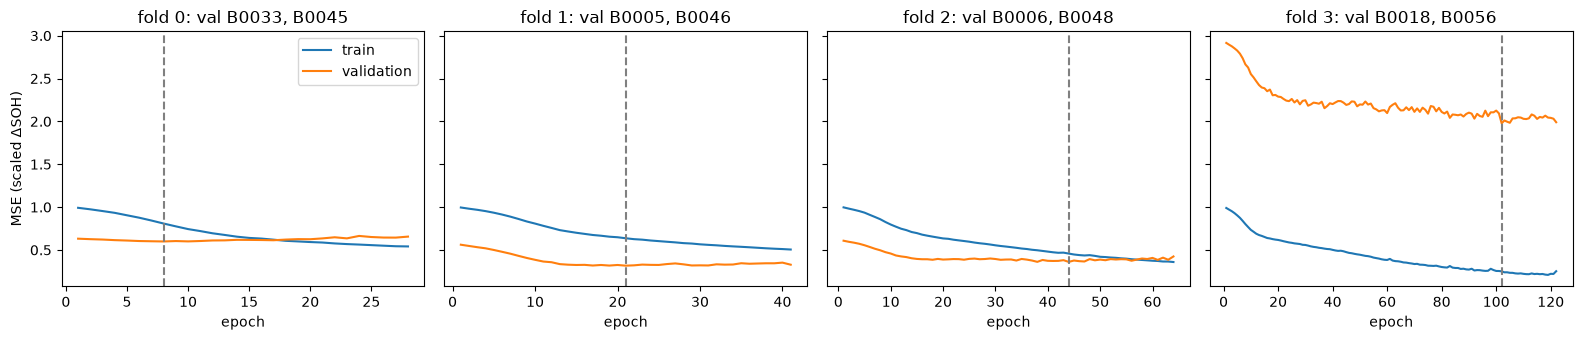

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for (k, h), ax in zip(curves[curves.seed == 42].groupby("fold"), axes):
    row = folds[(folds.seed == 42) & (folds.fold == k)].iloc[0]
    ax.plot(h.epoch, h.train_mse, label="train")
    ax.plot(h.epoch, h.val_mse, label="validation")
    ax.axvline(row.best_epoch, ls="--", c="grey")
    ax.set_title(f"fold {k}: val {row.val_batteries}")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE (scaled ΔSOH)")
axes[0].legend()
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "lstm_learning_curve.png", dpi=150)

**Reading the results.**

- Pooled validation RMSE: LSTM 0.0121 ± 0.0001 vs naive 0.0145 over 5 seeds, about 17% lower. The SD over seeds is small, so the gain is not a lucky initialisation.
- The LSTM beats naive on 19 of 20 fold–seed runs; the exception is fold 0 (B0033, B0045) with seed 45 (0.0122 vs 0.0121). On that fold the best epoch is 6–8 and the validation loss is flat from the start: the network adds little beyond naive for these two batteries.
- The best epoch varies widely between folds (6–116). The final model therefore uses the median best epoch of its seed (16–33 epochs) when refitted on all 8 training batteries.
- Fold 3 (B0018, B0056) has a much higher validation loss than the others: the two batteries are noisier (larger capacity jumps), as the naive RMSE of 0.0202 also shows. The curves show no clear over-fitting before early stopping; with 5,537 parameters for 831 windows, early stopping is what keeps it in check.
- These are validation results on training batteries. Test results (E1, E2) follow in C6.9.

## Step 5. Test forecasts E1 and E2 (C6.9)

For each seed, the model is refitted on all 8 training batteries for that seed's median best epoch (Step 4), then forecasts the `is_eval` rows (last 40%) of the 4 test batteries:

- **E1** one step ahead: the window holds true values up to *t−1*.
- **E2** recursive from the 60% origin: `soh_prev` is fed back from the forecast; `chg_cc_time_s`, `Re_ohm`, `Rct_ohm`, `log_rest_h` and `T_max_prev_C` keep their last value known at the origin (`docs/Rec.md` 6.1 #5).

`check_e2_no_peeking` scrambles every true value after the origin and checks that the E2 forecast does not change. `reports/predictions/lstm.csv` holds the mean of the 5 seed forecasts; the LSTM gives no prediction interval, so `y_lower` / `y_upper` stay empty.

In [9]:
from lstm_model import check_e2_no_peeking, fit_final, run_test
from protocol import PRED, evaluate

final_epochs = per_seed.final_epochs.astype(int).to_dict()
print("epochs per seed:", final_epochs)

model, scale = fit_final(train, 42, final_epochs[42])
for _, b in test.groupby("battery_id"):
    check_e2_no_peeking(model, scale, b)

seed_pred, lstm = run_test(train, test, final_epochs)
lstm.to_csv(PRED / "lstm.csv", index=False)
len(lstm)

epochs per seed: {42: 32, 43: 20, 44: 33, 45: 19, 46: 16}


426

Metrics of each seed on the 4 test batteries pooled, then mean ± SD over seeds.

In [10]:
seed_metrics, _ = evaluate(seed_pred)
pooled_seed = seed_metrics[seed_metrics.battery_id == "all"]
pooled_seed.groupby("scenario")[["MAE", "RMSE", "MAPE_pct", "R2"]].agg(["mean", "std"]).round(4)

MAE            RMSE         MAPE_pct              R2        
            mean     std    mean     std     mean     std    mean     std
scenario                                                                 
E1        0.0100  0.0002  0.0191  0.0003   1.2011  0.0205  0.6412  0.0110
E2        0.0393  0.0125  0.0523  0.0172   4.8458  1.5099 -1.9052  2.0199

The seed-mean LSTM next to the naive baseline (same rows, same `evaluate()`).

In [11]:
naive_pred = pd.read_csv(PRED / "naive.csv")
metrics, rul = evaluate(pd.concat([naive_pred, lstm], ignore_index=True))
display(metrics[metrics.battery_id == "all"].round(4))
display(metrics[metrics.battery_id != "all"].pivot_table(index="battery_id",
        columns=["scenario", "model"], values="RMSE").round(4))
rul

,model,scenario,battery_id,n,MAE,RMSE,MAPE_pct,R2
16,lstm,E1,all,213,0.0098,0.0190,1.1783,0.6467
17,lstm,E2,all,213,0.0303,0.0383,3.7430,-0.4364
18,naive,E1,all,213,0.0119,0.0226,1.4288,0.5001
19,naive,E2,all,213,0.0249,0.0343,3.1271,-0.1552


scenario        E1              E2        
model         lstm   naive    lstm   naive
battery_id                                
B0007       0.0025  0.0037  0.0361  0.0515
B0034       0.0085  0.0135  0.0381  0.0179
B0047       0.0089  0.0172  0.0489  0.0199
B0055       0.0414  0.0462  0.0335  0.0305

,model,battery_id,eol_true,eol_pred,rul_error
0,lstm,B0007,126.0,118.0,-8.0
1,lstm,B0034,186.0,150.0,-36.0
2,lstm,B0055,65.0,NaN,NaN
3,naive,B0007,126.0,NaN,NaN
4,naive,B0034,186.0,NaN,NaN
5,naive,B0055,65.0,NaN,NaN


Forecasts on the test batteries. The dotted line is the 60% origin, the dashed line SOH 0.8.

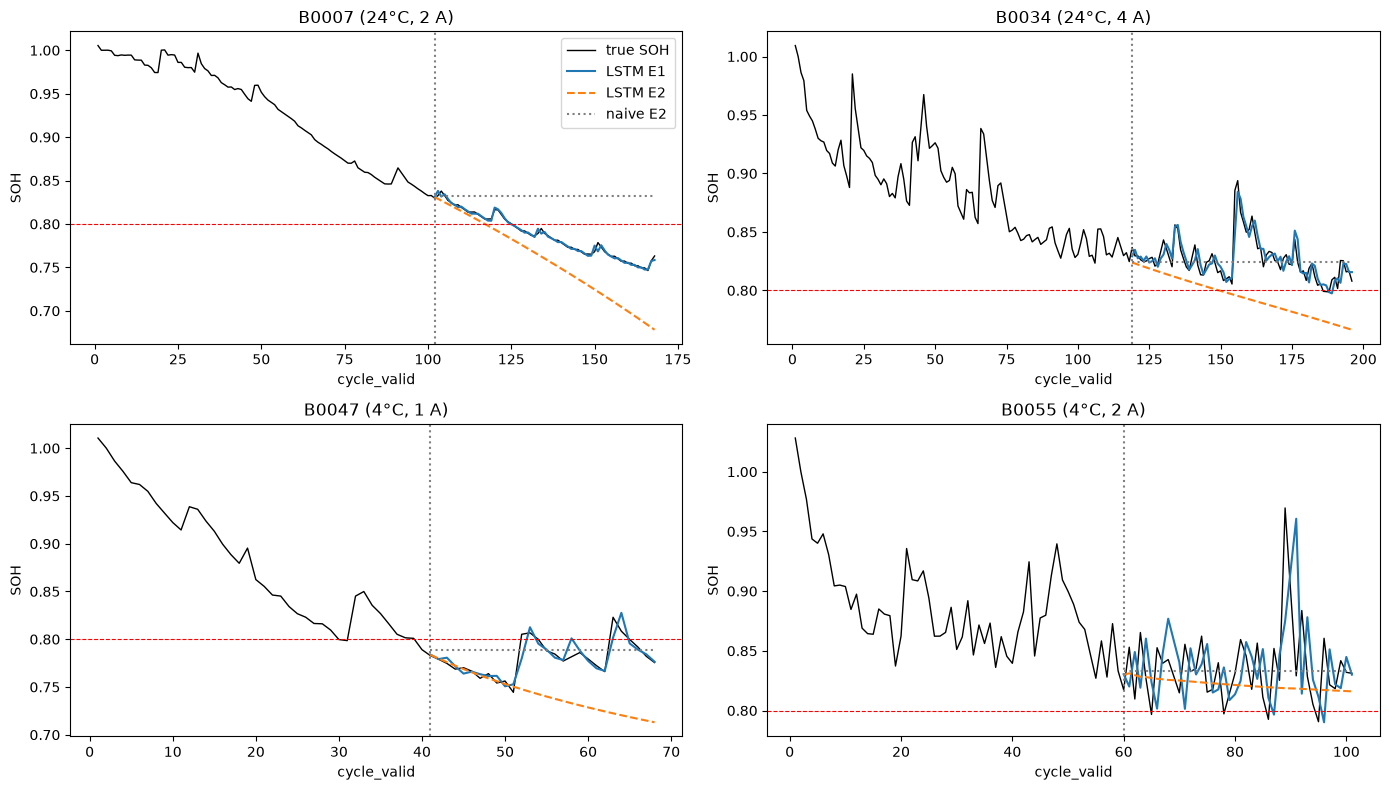

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for (bid, b), ax in zip(test.groupby("battery_id"), axes.flat):
    ax.plot(b.cycle_valid, b.soh, c="black", lw=1, label="true SOH")
    for scenario, style in (("E1", "-"), ("E2", "--")):
        p = lstm[(lstm.battery_id == bid) & (lstm.scenario == scenario)]
        ax.plot(p.cycle_valid, p.y_pred, style, label=f"LSTM {scenario}")
    p = naive_pred[(naive_pred.battery_id == bid) & (naive_pred.scenario == "E2")]
    ax.plot(p.cycle_valid, p.y_pred, ":", c="grey", label="naive E2")
    ax.axvline(b.cycle_valid[b.is_eval].iloc[0], ls=":", c="grey")
    ax.axhline(0.8, ls="--", c="red", lw=0.8)
    ax.set_title(f"{bid} ({b.ambient_C.iloc[0]:.0f}°C, {b.I_level_A.iloc[0]:.0f} A)")
    ax.set_xlabel("cycle_valid")
    ax.set_ylabel("SOH")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "lstm_forecasts.png", dpi=150)

**Reading the results.**

- **E1 (one step):** the LSTM beats naive on all 4 test batteries (pooled RMSE 0.0190 vs 0.0226, MAE 0.0098 vs 0.0119), and the SD over seeds is small. The figure shows why the gain is modest: the E1 curve mostly follows the previous true value with a small downward correction, so sudden jumps (capacity recovery after rest, e.g. B0055 near cycle 90) are reproduced one cycle late.
- **E2 (recursive):** the LSTM extrapolates a smooth, almost linear decline. Pooled RMSE 0.0383 is worse than the flat naive forecast (0.0343); it is better only on B0007, the battery with a steady fade. On B0034 and B0047 the forecast falls faster than the true SOH, because the recovery jumps cannot be forecast once the measured features are frozen at the origin.
- **RUL:** B0007 predicted 8 cycles early, B0034 36 cycles early, B0055 not reached (its true SOH crosses 0.8 only briefly, minimum 0.791). Early is the safe side for a warning, but 36 cycles is too early to be useful. Naive never predicts EOL, so it gives no RUL at all.
- **Seeds:** the seed-mean forecast (in `lstm.csv`) is better than the average single seed in E2 (RMSE 0.0383 vs 0.0523 ± 0.0172): single recursive runs drift in different directions and averaging cancels part of it.
- **Honest conclusion for RQ5:** with ~830 training windows the LSTM learns a useful one-step correction, but not a reliable long-horizon trajectory. These test results must not be used to tune the model further (that would leak the test set).